In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [8]:
CSV = Path("C:/Users/admin/source/repos/Kruskal/results/fk_threshold_sqrt2.csv")   
OUT = CSV.parent                               
NOISE_MS = 10   

In [9]:
df = pd.read_csv(CSV)
graph_order = list(df["graph"].unique())   

In [10]:
def geo(x):
    """Середнє геометричне"""
    return float(np.exp(np.log(x).mean()))

In [11]:
t = (df.groupby(["graph", "family", "V", "E", "pivot", "threshold"], as_index=False)
     .agg(mean_ms=("total_ms", "mean"),
            std_ms=("total_ms", "std"),
            runs=("total_ms", "size"),
            sorted_edges=("sorted_edges", "first")))

In [12]:
t["cv_pct"] = 100 * t["std_ms"] / t["mean_ms"]           
t["sorted_pct"] = 100 * t["sorted_edges"] / t["E"]
t["best_ms"] = t.groupby("graph")["mean_ms"].transform("min")
t["rel"] = t["mean_ms"] / t["best_ms"]                     
t["config"] = t["pivot"] + " t=" + t["threshold"].astype(str)

In [13]:
configs = (t[["pivot", "threshold", "config"]].drop_duplicates().sort_values(["pivot", "threshold"])["config"].tolist())

In [14]:
# відносний час кожної комбінації на кожному графі
rel_table = t.pivot_table(index="graph", columns="config", values="rel").reindex(index=graph_order, columns=configs)
print("Відносний час (1.000 = найкраща комбінація на графі):")
display(rel_table.round(3))

Відносний час (1.000 = найкраща комбінація на графі):


config,m3 t=2048,m3 t=4096,m3 t=8192,m3 t=16384,sqrt t=2048,sqrt t=4096,sqrt t=8192,sqrt t=16384
graph,,,,,,,,
B1,1.046,1.054,1.110,1.223,1.000,1.065,1.059,1.223
B2,1.064,1.070,1.033,1.162,1.050,1.025,1.047,1.000
B3,1.000,1.023,1.048,1.099,1.230,1.066,1.067,1.150
B4,1.000,1.135,1.068,1.186,1.385,1.364,1.370,1.344
B5,1.084,1.086,1.078,1.134,1.000,1.013,1.026,1.064
B6,1.029,1.022,1.055,1.000,1.225,1.208,1.205,1.223
B7,1.116,1.148,1.160,1.123,1.022,1.030,1.000,1.013
B8,1.002,1.011,1.000,1.019,1.219,1.270,1.239,1.244
B9,1.064,1.068,1.070,1.068,1.009,1.002,1.000,1.003


In [15]:
ms_table = t.pivot_table(index="graph", columns="config", values="mean_ms").reindex(index=graph_order, columns=configs)
print("Середній час, мс:")
display(ms_table.round(2))

Середній час, мс:


config,m3 t=2048,m3 t=4096,m3 t=8192,m3 t=16384,sqrt t=2048,sqrt t=4096,sqrt t=8192,sqrt t=16384
graph,,,,,,,,
B1,0.92,0.93,0.98,1.08,0.88,0.94,0.93,1.08
B2,1.18,1.18,1.14,1.28,1.16,1.13,1.16,1.10
B3,1.34,1.38,1.41,1.48,1.65,1.43,1.43,1.55
B4,1.75,1.99,1.87,2.08,2.43,2.39,2.40,2.36
B5,4.10,4.10,4.07,4.29,3.78,3.83,3.88,4.02
B6,6.09,6.04,6.24,5.91,7.24,7.14,7.13,7.24
B7,14.30,14.72,14.87,14.39,13.10,13.20,12.82,12.98
B8,20.93,21.12,20.88,21.28,25.46,26.53,25.88,25.99
B9,52.21,52.44,52.53,52.43,49.52,49.16,49.08,49.21


In [16]:
# Підсумок по всіх графах
def summarize(data):
    return (data.groupby("config")
                .agg(geo_rel=("rel", geo),                                  # типове відставання від найкращої
                     worst_rel=("rel", "max"),                              # найгірший граф
                     wins=("rel", lambda r: int((r == 1.0).sum())),         # на скількох графах найкраща
                     graphs=("rel", "size"))
                .sort_values("geo_rel"))

In [17]:
summary_all = summarize(t)
stable = t[t["best_ms"] >= NOISE_MS]
summary_stable = summarize(stable)

In [18]:
print("Усі графи:")
display(summary_all.round(4))
print(f"Лише графи, де час >= {NOISE_MS} мс ({stable['graph'].nunique()} графів):")
display(summary_stable.round(4))

Усі графи:


,geo_rel,worst_rel,wins,graphs
config,,,,
sqrt t=8192,1.0645,1.3698,4,19
m3 t=2048,1.0673,1.1590,2,19
sqrt t=16384,1.0712,1.3435,8,19
m3 t=8192,1.0728,1.1600,2,19
sqrt t=4096,1.0755,1.3641,0,19
m3 t=4096,1.0761,1.1603,0,19
sqrt t=2048,1.0825,1.3855,2,19
m3 t=16384,1.0906,1.2231,1,19


Лише графи, де час >= 10 мс (11 графів):


,geo_rel,worst_rel,wins,graphs
config,,,,
sqrt t=16384,1.0364,1.2444,6,11
sqrt t=8192,1.0387,1.2393,3,11
sqrt t=2048,1.0582,1.2189,0,11
sqrt t=4096,1.0622,1.2702,0,11
m3 t=16384,1.0659,1.1630,0,11
m3 t=8192,1.0716,1.1600,2,11
m3 t=2048,1.0791,1.1590,0,11
m3 t=4096,1.0798,1.1603,0,11


In [19]:
# По сім'ях графів (чи однаковий найкращий вибір для dense / grid / sparse)
family_table = (t.groupby(["family", "config"])["rel"].agg(geo)
                  .unstack("config").reindex(columns=configs))
print("Середнє геометричне відносного часу по сім'ях:")
display(family_table.round(3))

Середнє геометричне відносного часу по сім'ях:


config,m3 t=2048,m3 t=4096,m3 t=8192,m3 t=16384,sqrt t=2048,sqrt t=4096,sqrt t=8192,sqrt t=16384
family,,,,,,,,
dense,1.040,1.060,1.060,1.093,1.111,1.102,1.099,1.123
grid,1.137,1.140,1.119,1.086,1.041,1.020,1.016,1.000
sparse,1.102,1.093,1.087,1.088,1.045,1.042,1.019,1.005


In [20]:
# вплив способу вибору півота (sqrt / m3 при однаковому порогу)
piv = t.pivot_table(index=["graph", "threshold"], columns="pivot", values="mean_ms")
piv["sqrt_over_m3"] = piv["sqrt"] / piv["m3"]
print("sqrt / m3 (менше 1 означає, що sqrt швидший), середнє геометричне по графах:")
display(piv.groupby("threshold")["sqrt_over_m3"].agg(geo).round(3).to_frame())

sqrt / m3 (менше 1 означає, що sqrt швидший), середнє геометричне по графах:


,sqrt_over_m3
threshold,
2048,1.014
4096,0.999
8192,0.992
16384,0.982


In [21]:
# Висновок
best = summary_stable.index[0]
runner = summary_stable.index[1]
gap_pct = 100 * (summary_stable.loc[runner, "geo_rel"] / summary_stable.loc[best, "geo_rel"] - 1)
noise_pct = stable["cv_pct"].median()

print(f"Найкраща комбінація: {best}")
print(f"Друга: {runner}, повільніша в середньому на {gap_pct:.1f}%")
print(f"Типовий розкид між повторами: {noise_pct:.1f}%")
if gap_pct < noise_pct:
    print("Різниця менша за шум: варіанти практично рівноцінні, можна обрати простіший.")

Найкраща комбінація: sqrt t=16384
Друга: sqrt t=8192, повільніша в середньому на 0.2%
Типовий розкид між повторами: 1.4%
Різниця менша за шум: варіанти практично рівноцінні, можна обрати простіший.


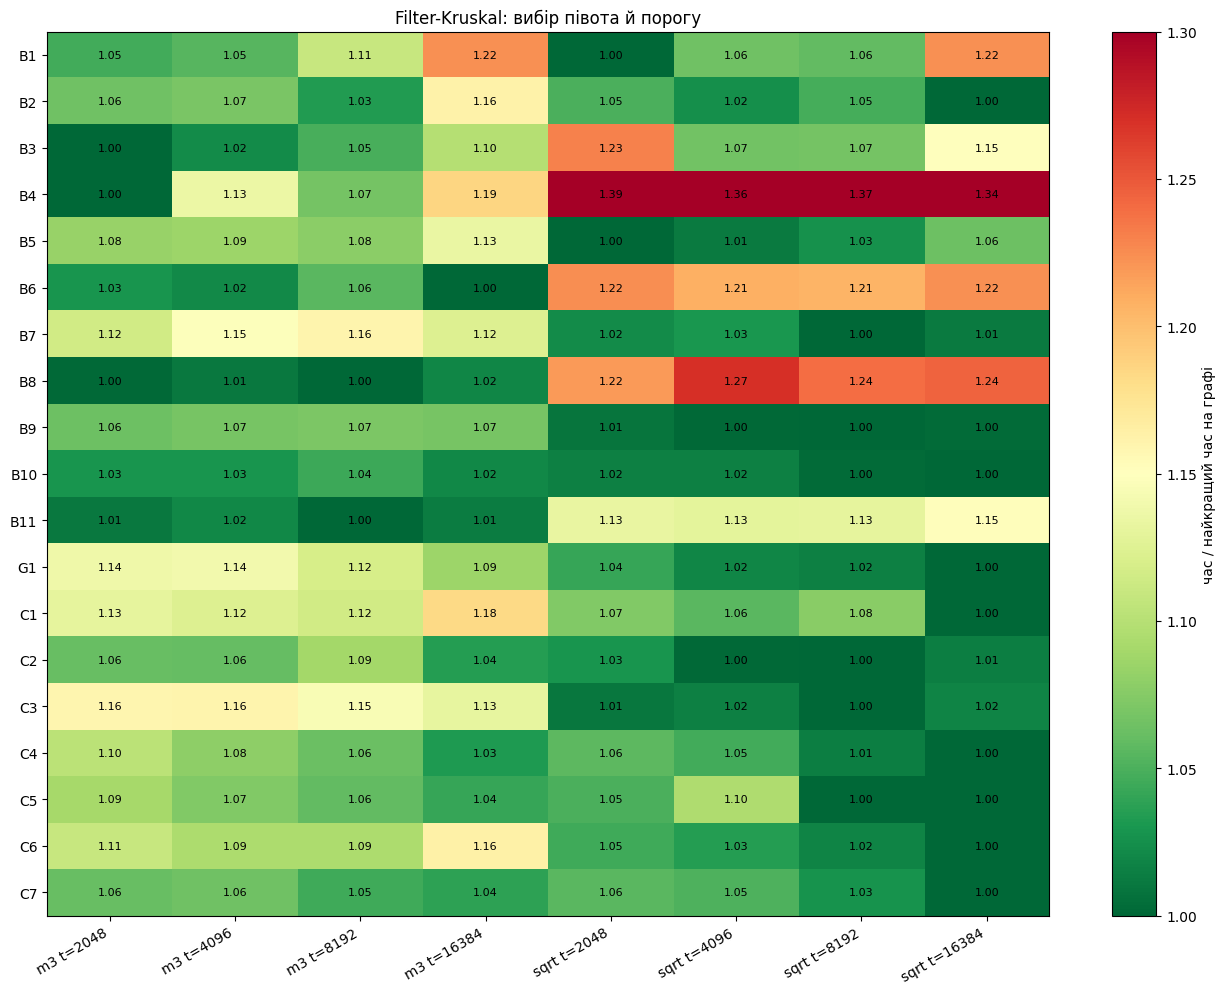

In [23]:
# теплова карта відносного часу
fig, ax = plt.subplots(figsize=(1.4 * len(configs) + 2, 0.45 * len(graph_order) + 1.5))
im = ax.imshow(rel_table.values, cmap="RdYlGn_r", vmin=1.0, vmax=min(1.3, np.nanmax(rel_table.values)), aspect="auto")
ax.set_xticks(range(len(configs)), configs, rotation=30, ha="right")
ax.set_yticks(range(len(graph_order)), graph_order)
for i in range(rel_table.shape[0]):
    for j in range(rel_table.shape[1]):
        ax.text(j, i, f"{rel_table.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="час / найкращий час на графі")
ax.set_title("Filter-Kruskal: вибір півота й порогу")
fig.tight_layout()
fig.savefig(OUT / "fk_tuning_heatmap.png", dpi=150)
plt.show()

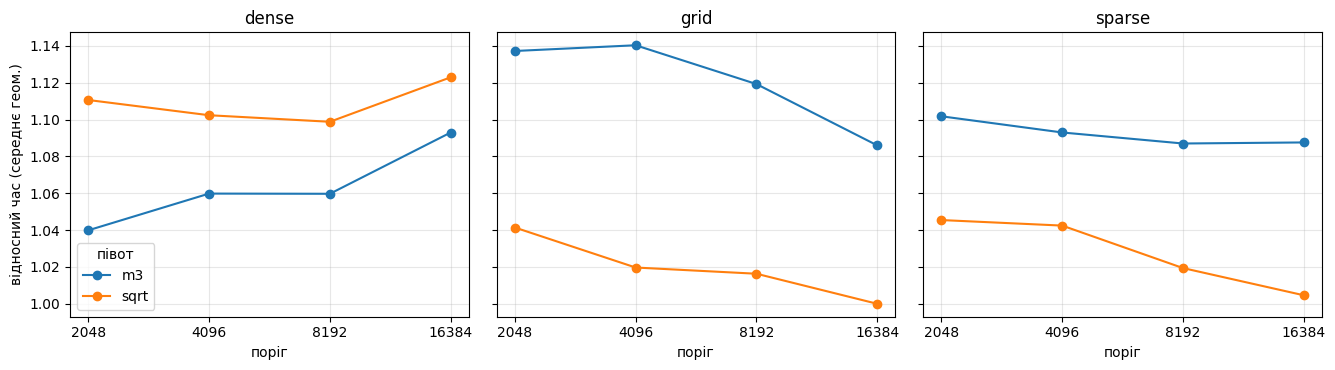

In [24]:
# відносний час від порогу, окремо по сім'ях
families = list(dict.fromkeys(t.set_index("graph").loc[graph_order, "family"]))
fig, axes = plt.subplots(1, len(families), figsize=(4.5 * len(families), 3.8), sharey=True)
for ax, family in zip(np.atleast_1d(axes), families):
    sub = t[t["family"] == family]
    for pivot, grp in sub.groupby("pivot"):
        line = grp.groupby("threshold")["rel"].agg(geo)
        ax.plot(line.index, line.values, marker="o", label=pivot)
    ax.set_xscale("log", base=2)
    ax.set_xticks(thresholds, [str(x) for x in thresholds])
    ax.set_title(family)
    ax.set_xlabel("поріг")
    ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel("відносний час (середнє геом.)")
np.atleast_1d(axes)[0].legend(title="півот")
fig.tight_layout()
fig.savefig(OUT / "fk_tuning_threshold.png", dpi=150)
plt.show()

In [25]:
# Частка відсортованих ребер для обраної комбінації
chosen = t[t["config"] == best].set_index("graph").reindex(graph_order)
display(chosen[["family", "V", "E", "mean_ms", "sorted_pct"]].round(2))

,family,V,E,mean_ms,sorted_pct
graph,,,,,
B1,dense,8000,16000,1.08,100.00
B2,dense,8000,32000,1.10,36.25
B3,dense,8000,64000,1.55,24.10
B4,dense,8000,128000,2.36,9.43
B5,dense,8000,256000,4.02,6.21
B6,dense,8000,512000,7.24,3.27
B7,dense,8000,1024000,12.98,1.37
B8,dense,8000,2048000,25.99,0.58
B9,dense,8000,4096000,49.21,0.29
